In [1]:
# Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix

In [5]:
# =====================================================
# STEP 1: LOAD AND PREPROCESS THE DATASET
# =====================================================

# 3C: Load Smart Grid Energy Consumption Dataset
df = pd.read_csv("energy consumption.csv")

In [6]:
# Convert timestamp into datetime
df['Timestamp'] = pd.to_datetime(
    df['Timestamp'], dayfirst=True
)

# Sort data according to timestamp
df = df.sort_values('Timestamp').reset_index(drop=True)

# Handle missing values
df = df.ffill().bfill()

# Select input features
features = [
    'Electricity_Consumed',
    'Temperature',
    'Humidity',
    'Wind_Speed',
    'Avg_Past_Consumption'
]

X = df[features].values
y = df['Anomaly_Label'].values

# Split data chronologically: 70% train, 15% validation, 15% test
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train_raw = X[:train_end]
X_val_raw = X[train_end:val_end]
X_test_raw = X[val_end:]

y_train = y[:train_end]
y_val = y[train_end:val_end]
y_test = y[val_end:]

# Normalize data using normal training records only
scaler = MinMaxScaler()

scaler.fit(X_train_raw[y_train == 0])

X_train = scaler.transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)


In [7]:
# =====================================================
# STEP 2: CREATE TIME WINDOWS
# =====================================================

# Create time windows
TIME_STEPS = 24

def create_sequences(data, labels, time_steps):
    sequences = []
    sequence_labels = []

    for i in range(len(data) - time_steps + 1):
        sequences.append(data[i:i + time_steps])

        # Window is anomalous if any record is anomalous
        sequence_labels.append(
            int(np.max(labels[i:i + time_steps]))
        )

    return np.array(sequences), np.array(sequence_labels)

X_train_seq, y_train_seq = create_sequences(
    X_train, y_train, TIME_STEPS
)

X_val_seq, y_val_seq = create_sequences(
    X_val, y_val, TIME_STEPS
)

X_test_seq, y_test_seq = create_sequences(
    X_test, y_test, TIME_STEPS
)

# Keep only normal sequences for training
X_train_normal = X_train_seq[y_train_seq == 0]

# Keep normal sequences for threshold calculation
X_val_normal = X_val_seq[y_val_seq == 0]

print("Training sequences:", X_train_normal.shape)
print("Validation sequences:", X_val_seq.shape)
print("Testing sequences:", X_test_seq.shape)

Training sequences: (1515, 24, 5)
Validation sequences: (727, 24, 5)
Testing sequences: (727, 24, 5)


In [10]:
# =====================================================
# STEP 3: DEFINE LSTM AUTOENCODER MODEL
# =====================================================

# Define LSTM Autoencoder
model = keras.Sequential([

    # Encoder
    layers.Input(shape=(TIME_STEPS, len(features))),

    layers.LSTM(64, activation='relu',
                return_sequences=False),

    # Latent representation
    layers.RepeatVector(TIME_STEPS),

    # Decoder
    layers.LSTM(64, activation='relu',
                return_sequences=True),

    layers.TimeDistributed(
        layers.Dense(len(features))
    )
])



In [11]:
# =====================================================
# STEP 4: COMPILE THE MODEL
# =====================================================

# Compile model
model.compile(
    optimizer='adam',
    loss='mse'
)

# Display model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                        │ (None, 64)                  │          17,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_1 (RepeatVector)       │ (None, 24, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 24, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_1 (TimeDistributed) │ (None, 24, 5)               │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 51,269 (200.27 KB)

 Trainable params: 51,269 (200.27 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# =====================================================
# STEP 5: TRAIN THE MODEL
# =====================================================

# Train only on normal consumption data
history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_normal, X_val_normal),
    shuffle=True
)

Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 139ms/step - loss: 0.0783 - val_loss: 0.0350
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - loss: 0.0292 - val_loss: 0.0260
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - loss: 0.0240 - val_loss: 0.0246
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - loss: 0.0232 - val_loss: 0.0241
Epoch 5/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - loss: 0.0227 - val_loss: 0.0234
Epoch 6/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - loss: 0.0223 - val_loss: 0.0232
Epoch 7/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - loss: 0.0218 - val_loss: 0.0228
Epoch 8/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - loss: 0.0215 - val_loss: 0.0224
Epoch 9/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - loss: 0.0212 - val_loss: 0.0222
Epoch 10/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - loss: 0.0210 - val_loss: 0.0221
Epoch 11/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - loss: 0.0210 - val_loss: 0.0221
Epoch 12/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - loss: 0

In [15]:
# =====================================================
# STEP 6: CALCULATE RECONSTRUCTION ERROR
# =====================================================

# Reconstruct training and testing data
train_pred = model.predict(X_train_normal)
test_pred = model.predict(X_test_seq)

# Calculate Mean Squared Reconstruction Error
train_error = np.mean(
    np.square(X_train_normal - train_pred), axis=(1, 2)
)

test_error = np.mean(
    np.square(X_test_seq - test_pred), axis=(1, 2)
)

# Set threshold using 95th percentile
threshold = np.percentile(train_error, 95)

print("Anomaly Threshold:", threshold)

# Detect anomalies
anomalies = (test_error > threshold).astype(int)
print("Detected Anomalies:", np.sum(anomalies))

48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step
Anomaly Threshold: 0.02379461849626732
Detected Anomalies: 134


In [16]:
# =====================================================
# STEP 7: EVALUATE ANOMALY DETECTION
# =====================================================

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_seq, anomalies))

print("\nClassification Report:")
print(classification_report(
    y_test_seq, anomalies,
    target_names=['Normal', 'Abnormal'],
    zero_division=0
))


Confusion Matrix:
[[352  29]
 [241 105]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.59      0.92      0.72       381
    Abnormal       0.78      0.30      0.44       346

    accuracy                           0.63       727
   macro avg       0.69      0.61      0.58       727
weighted avg       0.68      0.63      0.59       727



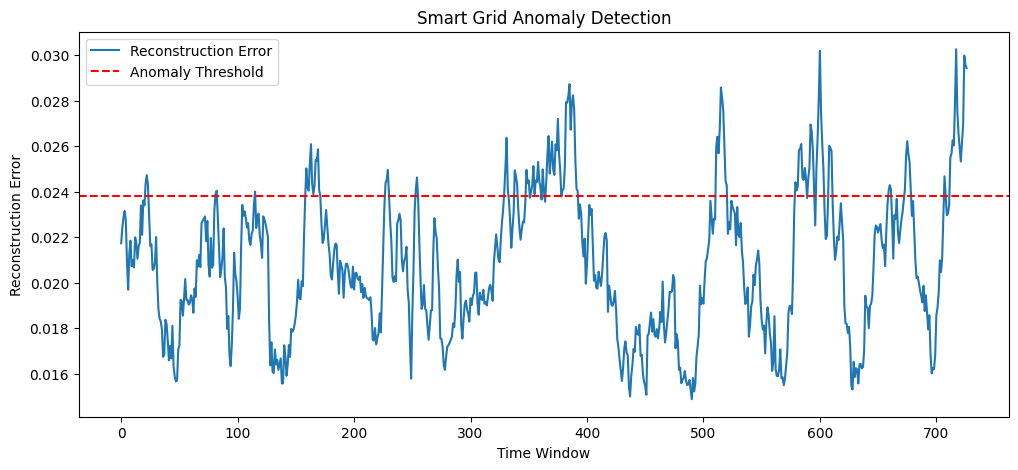

In [17]:
# =====================================================
# STEP 8: DISPLAY ANOMALY RESULTS
# =====================================================

plt.figure(figsize=(12, 5))

plt.plot(test_error, label='Reconstruction Error')
plt.axhline(
    y=threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title('Smart Grid Anomaly Detection')
plt.xlabel('Time Window')
plt.ylabel('Reconstruction Error')
plt.legend()
plt.show()

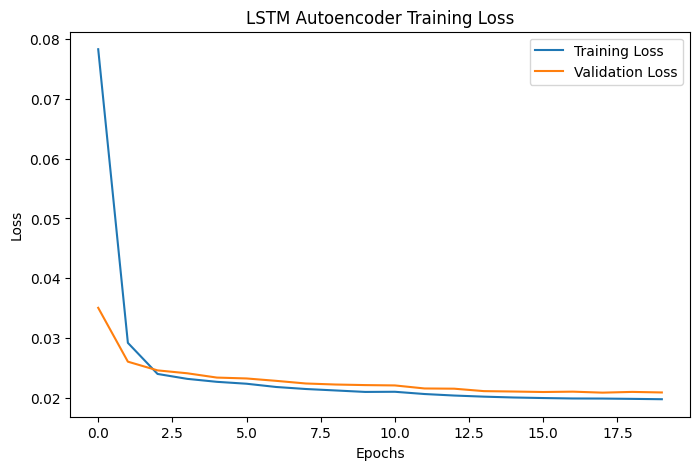

In [18]:
# =====================================================
# STEP 9: PLOT TRAINING LOSS
# =====================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('LSTM Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [19]:
# Display detected anomaly status
for i in range(min(10, len(anomalies))):
    if anomalies[i] == 1:
        print("Window", i, ": Anomaly Detected")
    else:
        print("Window", i, ": Normal")

Window 0 : Normal
Window 1 : Normal
Window 2 : Normal
Window 3 : Normal
Window 4 : Normal
Window 5 : Normal
Window 6 : Normal
Window 7 : Normal
Window 8 : Normal
Window 9 : Normal
